#  Task 4 — Weather Forecast API & Time-Series EDA
**Region:** Alexandria, Egypt (31.2°N, 29.9°E)  
**API:** NASA POWER (free, no strict key required)  
**Period:** 2022-01-01 → 2023-12-31 (2 full years, daily)  
**Variables:** T2M_MAX, T2M_MIN, T2M (temperature °C), PRECTOTCORR (precipitation mm), RH2M (humidity %), WS2M (wind speed m/s)

---
## Install & Import Libraries

In [1]:
import requests
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from scipy import stats

import warnings
warnings.filterwarnings('ignore')

# ── Plot style ──────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11
})
sns.set_palette('tab10')

print('✅ All libraries imported successfully')

✅ All libraries imported successfully


---
## 🛰️ Part 1 — API Data Collection (NASA POWER)

### 1.1  API Configuration

**Why NASA POWER?**
- Completely free — no API key required
- Historical daily data going back to 1981
- Covers any coordinate worldwide
- Returns JSON with clear parameter names and SI units

**Endpoint:** `https://power.larc.nasa.gov/api/temporal/daily/point`

In [2]:
# ── Region & time range ──────────────────────────────────────────────────────
LATITUDE  = 31.2001   # Alexandria, Egypt
LONGITUDE = 29.9187
START     = '20220101'
END       = '20231231'

# Parameters requested
PARAMS = ','.join([
    'T2M',           # Mean temperature at 2 m (°C)
    'T2M_MAX',       # Max temperature at 2 m (°C)
    'T2M_MIN',       # Min temperature at 2 m (°C)
    'PRECTOTCORR',   # Precipitation corrected (mm/day)
    'RH2M',          # Relative humidity at 2 m (%)
    'WS2M',          # Wind speed at 2 m (m/s)
])

BASE_URL = 'https://power.larc.nasa.gov/api/temporal/daily/point'

payload = {
    'parameters': PARAMS,
    'community'  : 'RE',          # Renewable Energy community
    'longitude'  : LONGITUDE,
    'latitude'   : LATITUDE,
    'start'      : START,
    'end'        : END,
    'format'     : 'JSON',
}

print('🌍 Target region  : Alexandria, Egypt')
print(f'📍 Coordinates    : {LATITUDE}°N, {LONGITUDE}°E')
print(f'📅 Time range     : {START} → {END}  (2 full years, daily)')
print(f'📊 Parameters     : {PARAMS}')

🌍 Target region  : Alexandria, Egypt
📍 Coordinates    : 31.2001°N, 29.9187°E
📅 Time range     : 20220101 → 20231231  (2 full years, daily)
📊 Parameters     : T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,WS2M


### 1.2  Send Request & Save Raw Response

In [3]:
print('⏳ Sending request to NASA POWER API ...')
response = requests.get(BASE_URL, params=payload, timeout=120)

print(f'📡 Status code    : {response.status_code}')
print(f'📦 Response size  : {len(response.content) / 1024:.1f} KB')

if response.status_code != 200:
    raise RuntimeError(f'API error: {response.status_code}\n{response.text[:500]}')

raw_data = response.json()

# Save raw JSON response
with open('raw_api_response.json', 'w') as f:
    json.dump(raw_data, f, indent=2)

print('\n✅ Raw response saved → raw_api_response.json')

# Quick peek at metadata
meta = raw_data.get('header', {})
print(f"\nAPI Metadata:")
print(f"  Fill value (missing)  : {raw_data['parameters']['T2M'].get('fill', 'N/A')}")
print(f"  Temporal resolution  : daily")
print(f"  Units: T2M=°C | PRECTOTCORR=mm/day | RH2M=% | WS2M=m/s")

⏳ Sending request to NASA POWER API ...
📡 Status code    : 200
📦 Response size  : 71.2 KB

✅ Raw response saved → raw_api_response.json

API Metadata:
  Fill value (missing)  : N/A
  Temporal resolution  : daily
  Units: T2M=°C | PRECTOTCORR=mm/day | RH2M=% | WS2M=m/s


### 1.3  Parse API Response → DataFrame

In [4]:
# Extract the nested 'properties → parameter' dictionary
param_data = raw_data['properties']['parameter']

# Build DataFrame — each key is a variable, values are {YYYYMMDD: value}
df_raw = pd.DataFrame(param_data)
df_raw.index.name = 'date_str'
df_raw.reset_index(inplace=True)

# Rename columns for readability
df_raw.rename(columns={
    'T2M'        : 'temp_mean',
    'T2M_MAX'    : 'temp_max',
    'T2M_MIN'    : 'temp_min',
    'PRECTOTCORR': 'precipitation',
    'RH2M'       : 'humidity',
    'WS2M'       : 'wind_speed',
}, inplace=True)

print(f'Raw shape: {df_raw.shape}')
print('\nColumn types before cleaning:')
print(df_raw.dtypes)
df_raw.head()

Raw shape: (730, 7)

Column types before cleaning:
date_str          object
temp_mean        float64
temp_max         float64
temp_min         float64
precipitation    float64
humidity         float64
wind_speed       float64
dtype: object


,date_str,temp_mean,temp_max,temp_min,precipitation,humidity,wind_speed
0,20220101,12.99,18.40,8.62,0.08,77.98,1.57
1,20220102,14.08,17.51,11.03,3.10,88.24,1.91
2,20220103,14.87,19.82,12.06,0.04,84.38,2.53
3,20220104,14.23,18.56,11.39,0.25,81.51,2.95
4,20220105,13.89,19.50,10.10,0.02,75.31,1.78


---
##  Part 2 — Data Preparation

### 2.1  Parse Dates & Set Datetime Index

In [5]:
df = df_raw.copy()

# Parse YYYYMMDD string → datetime
df['date'] = pd.to_datetime(df['date_str'], format='%Y%m%d')
df.drop(columns=['date_str'], inplace=True)
df.set_index('date', inplace=True)
df.sort_index(inplace=True)

print(f'Date range   : {df.index.min().date()}  →  {df.index.max().date()}')
print(f'Total rows   : {len(df)}')
print(f'Expected rows: {(pd.Timestamp("2023-12-31") - pd.Timestamp("2022-01-01")).days + 1}')
print(f'Index dtype  : {df.index.dtype}')
df.head()

Date range   : 2022-01-01  →  2023-12-31
Total rows   : 730
Expected rows: 730
Index dtype  : datetime64[ns]


,temp_mean,temp_max,temp_min,precipitation,humidity,wind_speed
date,,,,,,
2022-01-01,12.99,18.40,8.62,0.08,77.98,1.57
2022-01-02,14.08,17.51,11.03,3.10,88.24,1.91
2022-01-03,14.87,19.82,12.06,0.04,84.38,2.53
2022-01-04,14.23,18.56,11.39,0.25,81.51,2.95
2022-01-05,13.89,19.50,10.10,0.02,75.31,1.78


### 2.2  Check Sampling Frequency — Gaps & Duplicates

In [6]:
# Check for duplicated timestamps
n_dupes = df.index.duplicated().sum()
print(f'Duplicated timestamps : {n_dupes}')

# Check for gaps (missing days)
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='D')
missing_dates = full_range.difference(df.index)
print(f'Missing dates         : {len(missing_dates)}')

# Inferred frequency
print(f'Inferred frequency    : {pd.infer_freq(df.index)}')

if len(missing_dates) > 0:
    print(f'\nMissing date list:\n{missing_dates}')

Duplicated timestamps : 0
Missing dates         : 0
Inferred frequency    : D


### 2.3  Handle Missing Values (NASA POWER Fill Value = -999)

In [7]:
# NASA POWER uses -999 as a sentinel for missing/invalid values
FILL_VALUE = -999.0

# Replace fill values with NaN
df.replace(FILL_VALUE, np.nan, inplace=True)

# Precipitation can't be negative — flag as NaN
df.loc[df['precipitation'] < 0, 'precipitation'] = np.nan

print('Missing values per column (after replacing -999 → NaN):')
missing = df.isnull().sum()
pct     = (df.isnull().mean() * 100).round(2)
print(pd.concat([missing.rename('count'), pct.rename('pct %')], axis=1))

Missing values per column (after replacing -999 → NaN):
               count  pct %
temp_mean          0    0.0
temp_max           0    0.0
temp_min           0    0.0
precipitation      0    0.0
humidity           0    0.0
wind_speed         0    0.0


In [8]:
# Strategy: linear interpolation for temperature & humidity (continuous)
#           forward-fill for precipitation (sparse events)
# Rationale: interpolation preserves smooth trend for temp;
#            precipitation is event-based so ffill avoids inventing rain.

cols_interpolate = ['temp_mean', 'temp_max', 'temp_min', 'humidity', 'wind_speed']
cols_ffill       = ['precipitation']

df[cols_interpolate] = df[cols_interpolate].interpolate(method='linear', limit_direction='both')
df[cols_ffill]       = df[cols_ffill].ffill().bfill()

print('Missing values AFTER imputation:')
print(df.isnull().sum())

Missing values AFTER imputation:
temp_mean        0
temp_max         0
temp_min         0
precipitation    0
humidity         0
wind_speed       0
dtype: int64


### 2.4  Confirm Units & Save Clean CSV

In [9]:
print('Units confirmation:')
print('  temp_mean / temp_max / temp_min  →  °C   (NASA POWER default for T2M)')
print('  precipitation                    →  mm/day')
print('  humidity                         →  %')
print('  wind_speed                       →  m/s')

# Sanity checks
assert df['temp_mean'].between(-60, 60).all(),  "Temperature out of plausible range!"
assert df['precipitation'].ge(0).all(),         "Negative precipitation found!"
assert df['humidity'].between(0, 100).all(),    "Humidity out of 0-100% range!"

# Save cleaned dataset
df.to_csv('alexandria_weather_clean.csv')
print('\n✅ Clean dataset saved → alexandria_weather_clean.csv')
print(f'   Shape: {df.shape}')
df.head()

Units confirmation:
  temp_mean / temp_max / temp_min  →  °C   (NASA POWER default for T2M)
  precipitation                    →  mm/day
  humidity                         →  %
  wind_speed                       →  m/s

✅ Clean dataset saved → alexandria_weather_clean.csv
   Shape: (730, 6)


,temp_mean,temp_max,temp_min,precipitation,humidity,wind_speed
date,,,,,,
2022-01-01,12.99,18.40,8.62,0.08,77.98,1.57
2022-01-02,14.08,17.51,11.03,3.10,88.24,1.91
2022-01-03,14.87,19.82,12.06,0.04,84.38,2.53
2022-01-04,14.23,18.56,11.39,0.25,81.51,2.95
2022-01-05,13.89,19.50,10.10,0.02,75.31,1.78


---
##  Part 3 — Exploratory Data Analysis (Time-Series Focus)

### 3.1  Descriptive Statistics

In [10]:
print('='*60)
print('SUMMARY STATISTICS')
print('='*60)
df.describe().T.round(2)

SUMMARY STATISTICS


,count,mean,std,min,25%,50%,75%,max
temp_mean,730.0,21.82,5.66,9.74,17.18,22.04,27.17,33.83
temp_max,730.0,27.49,6.48,12.33,22.18,27.92,33.10,42.92
temp_min,730.0,17.40,5.22,5.90,12.88,17.30,22.28,27.10
precipitation,730.0,0.49,1.96,0.00,0.00,0.00,0.05,22.27
humidity,730.0,64.37,7.80,37.67,60.18,64.24,69.01,88.24
wind_speed,730.0,3.27,1.01,0.91,2.62,3.23,3.80,7.12


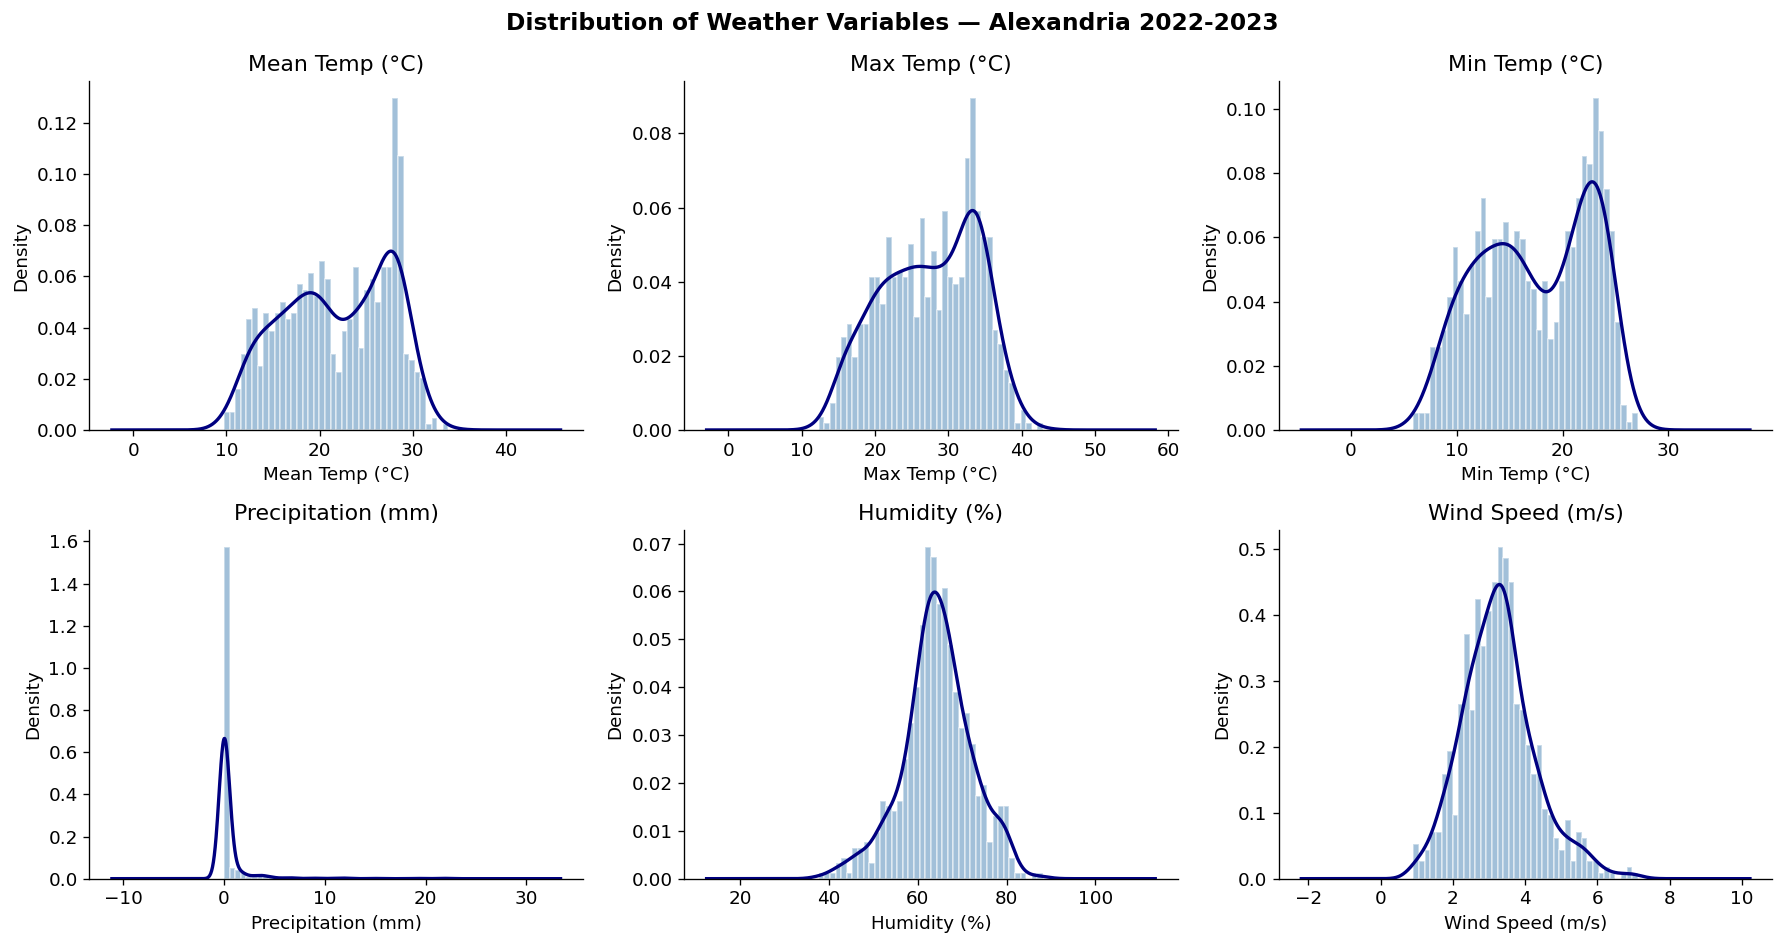

In [11]:
# Distribution plots — histogram + KDE for each variable
cols   = ['temp_mean', 'temp_max', 'temp_min', 'precipitation', 'humidity', 'wind_speed']
titles = ['Mean Temp (°C)', 'Max Temp (°C)', 'Min Temp (°C)',
          'Precipitation (mm)', 'Humidity (%)', 'Wind Speed (m/s)']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Distribution of Weather Variables — Alexandria 2022-2023', fontsize=14, fontweight='bold')

for ax, col, title in zip(axes.flat, cols, titles):
    ax.hist(df[col], bins=40, density=True, alpha=0.5, color='steelblue', edgecolor='white')
    df[col].plot(kind='kde', ax=ax, color='navy', linewidth=2)
    ax.set_title(title)
    ax.set_ylabel('Density')
    ax.set_xlabel(title)

plt.tight_layout()
plt.savefig('fig1_distributions.png', bbox_inches='tight')
plt.show()

### 3.2  Temporal Patterns

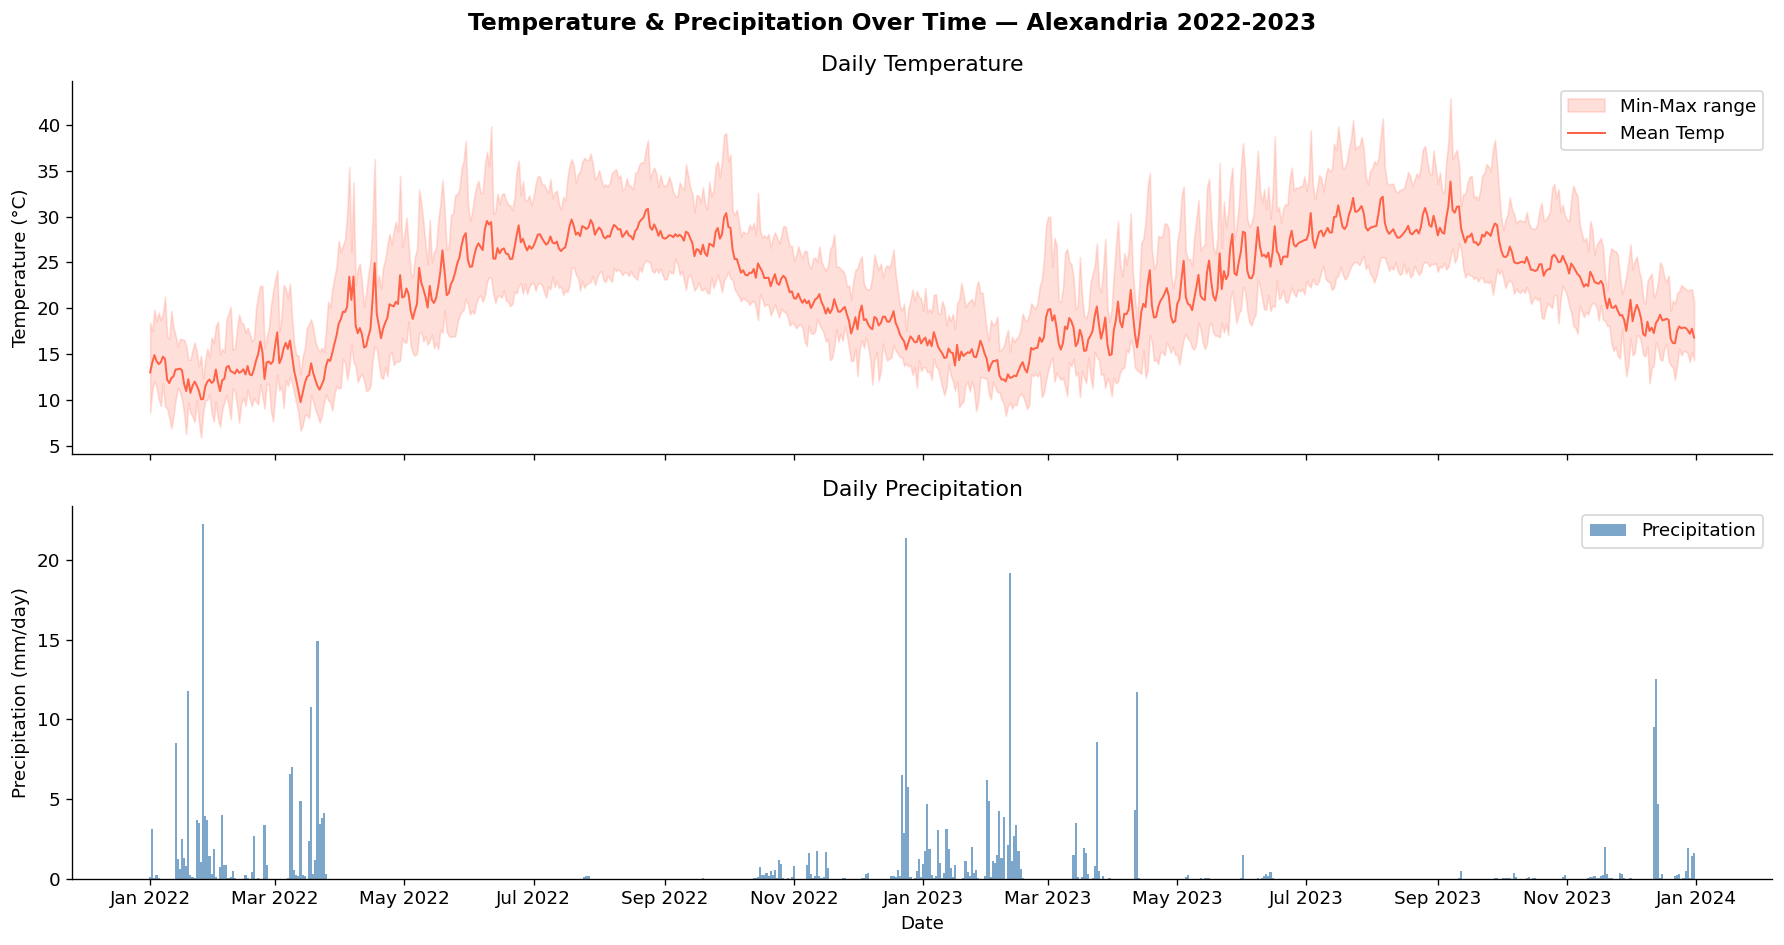

In [12]:
# ── Full time-range line plots ───────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
fig.suptitle('Temperature & Precipitation Over Time — Alexandria 2022-2023',
             fontsize=14, fontweight='bold')

# Temperature
ax1.fill_between(df.index, df['temp_min'], df['temp_max'], alpha=0.2, color='tomato', label='Min-Max range')
ax1.plot(df.index, df['temp_mean'], color='tomato', linewidth=1.2, label='Mean Temp')
ax1.set_ylabel('Temperature (°C)')
ax1.legend()
ax1.set_title('Daily Temperature')

# Precipitation
ax2.bar(df.index, df['precipitation'], width=1, color='steelblue', alpha=0.7, label='Precipitation')
ax2.set_ylabel('Precipitation (mm/day)')
ax2.set_xlabel('Date')
ax2.legend()
ax2.set_title('Daily Precipitation')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))

plt.tight_layout()
plt.savefig('fig2_timeseries.png', bbox_inches='tight')
plt.show()

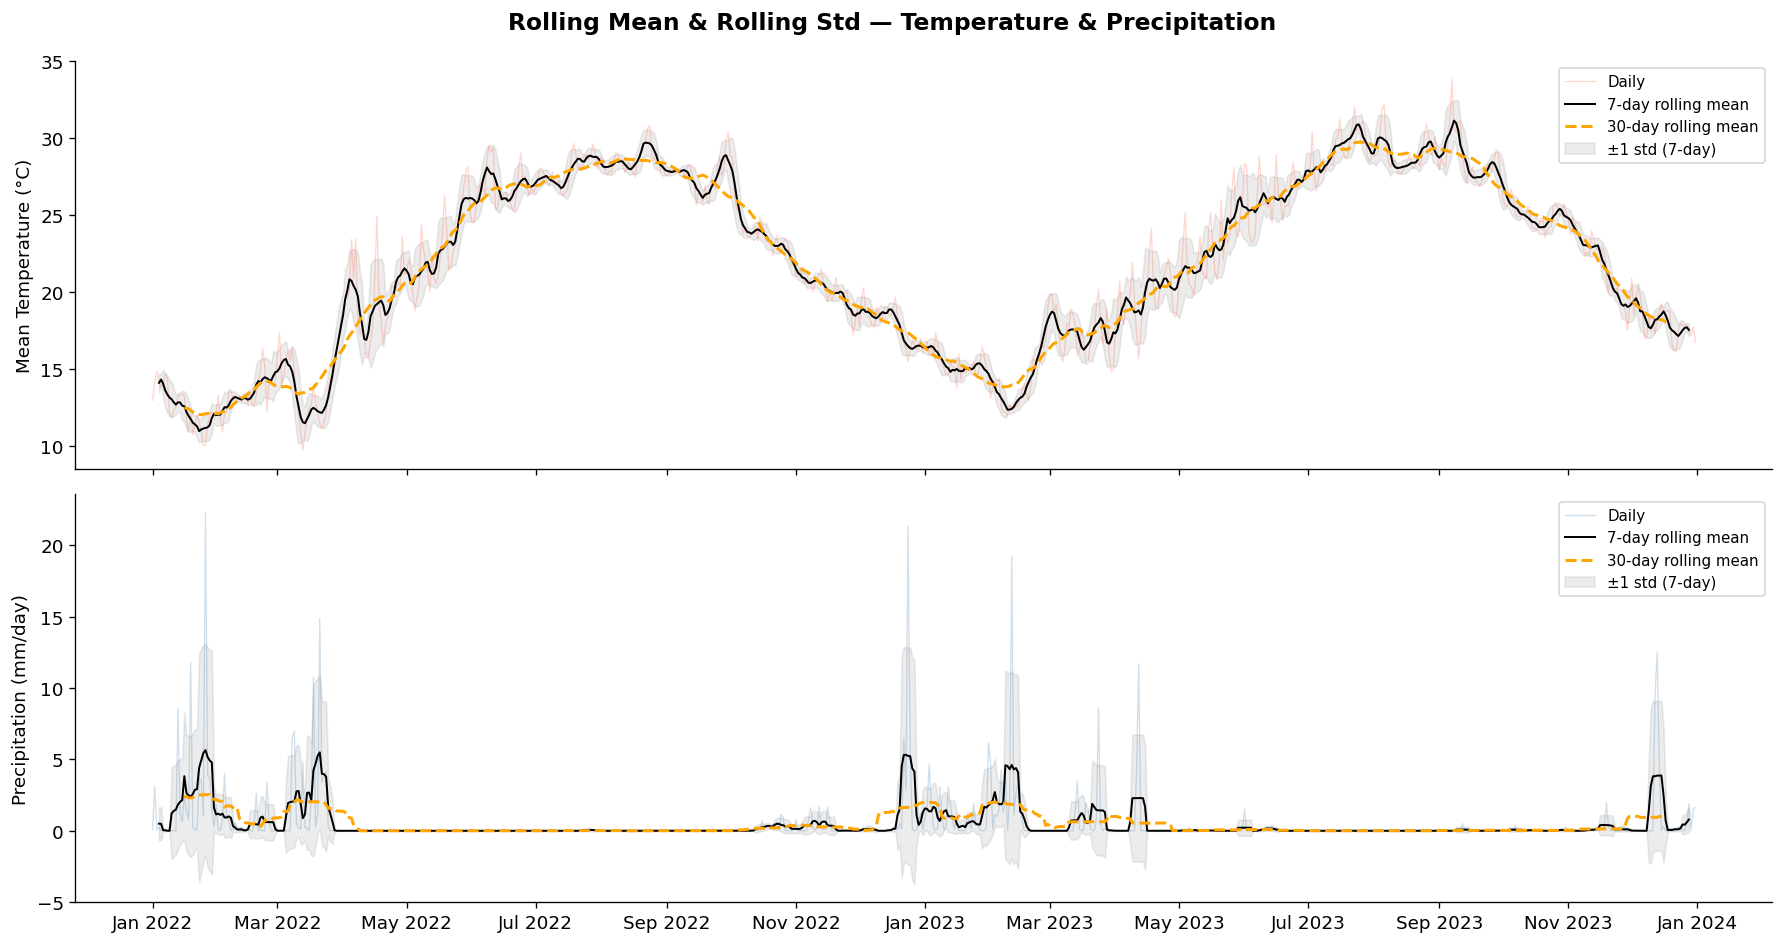

In [13]:
# ── Rolling statistics — trend analysis ─────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
fig.suptitle('Rolling Mean & Rolling Std — Temperature & Precipitation', fontsize=14, fontweight='bold')

for ax, col, title, color in [
        (axes[0], 'temp_mean',     'Mean Temperature (°C)',   'tomato'),
        (axes[1], 'precipitation', 'Precipitation (mm/day)', 'steelblue')]:

    roll7  = df[col].rolling(7,  center=True).mean()
    roll30 = df[col].rolling(30, center=True).mean()
    roll7_std  = df[col].rolling(7, center=True).std()

    ax.plot(df.index, df[col],  alpha=0.25, color=color, linewidth=0.8, label='Daily')
    ax.plot(df.index, roll7,    color='black',  linewidth=1.2, label='7-day rolling mean')
    ax.plot(df.index, roll30,   color='orange', linewidth=1.8, linestyle='--', label='30-day rolling mean')
    ax.fill_between(df.index,
                    roll7 - roll7_std, roll7 + roll7_std,
                    alpha=0.15, color='grey', label='±1 std (7-day)')
    ax.set_ylabel(title)
    ax.legend(fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))

plt.tight_layout()
plt.savefig('fig3_rolling_stats.png', bbox_inches='tight')
plt.show()

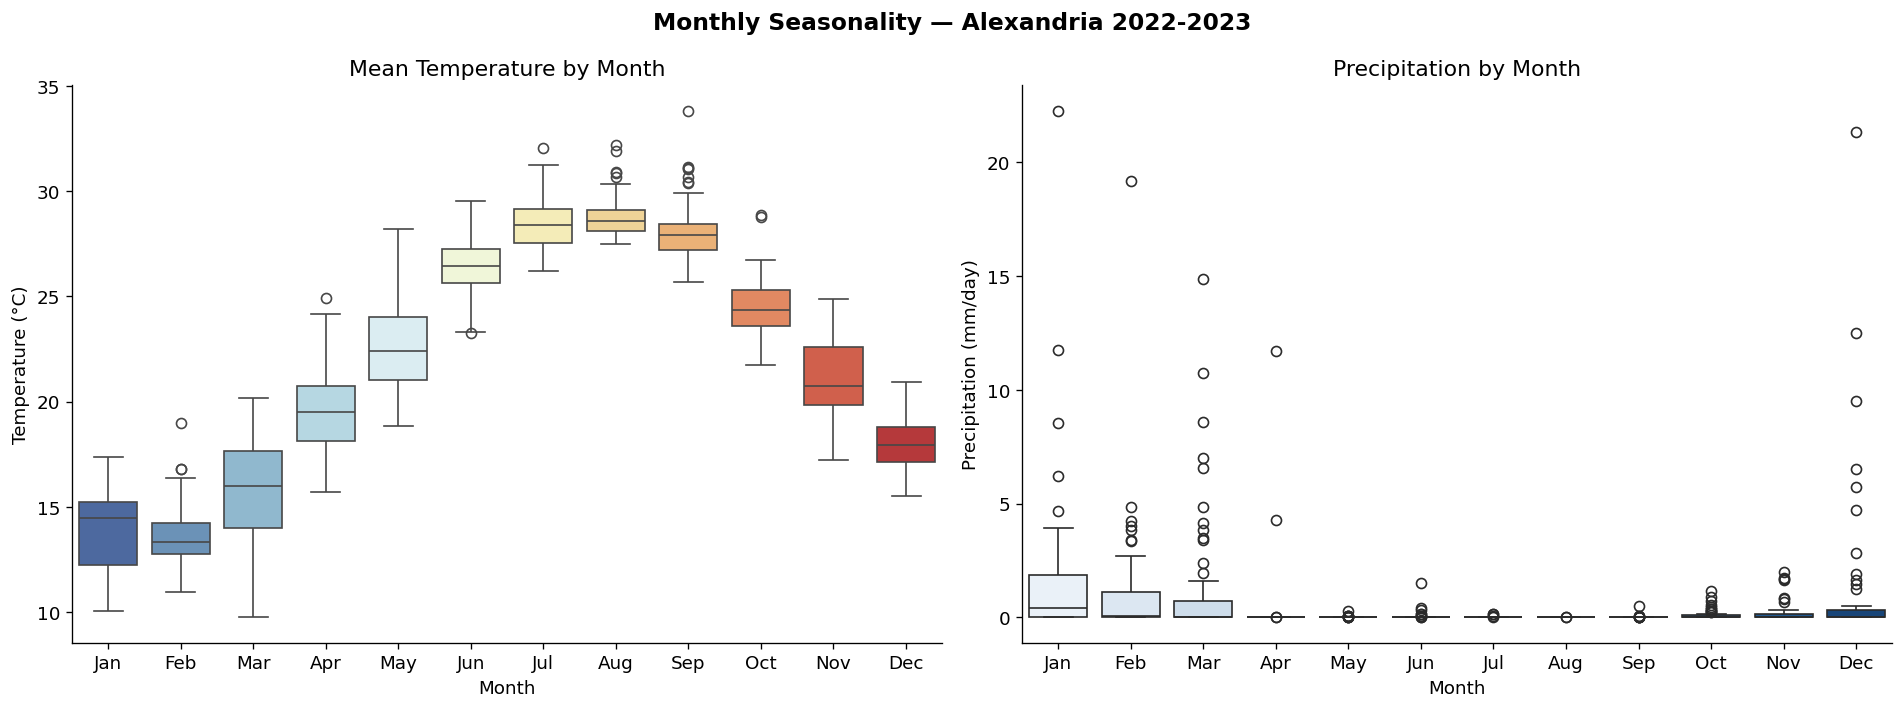


Monthly aggregates:


temp_mean       precipitation       humidity      
           mean   std          mean   std     mean   std
month                                                   
1         13.96  1.85          1.68  3.42    72.02  6.94
2         13.72  1.49          1.13  2.78    70.05  5.44
3         15.61  2.60          1.29  2.85    65.53  7.01
4         19.61  2.06          0.27  1.60    61.40  7.77
5         22.86  2.27          0.01  0.04    60.39  7.83
6         26.50  1.46          0.04  0.20    61.27  6.49
7         28.56  1.34          0.01  0.03    61.19  4.42
8         28.82  1.02          0.00  0.00    61.03  5.55
9         28.13  1.48          0.01  0.06    60.30  5.53
10        24.53  1.37          0.11  0.23    64.83  4.97
11        21.01  1.83          0.20  0.45    63.47  7.88
12        18.01  1.18          1.19  3.46    71.19  8.20

In [14]:
# ── Seasonality — boxplots by month ─────────────────────────────────────────
df['month']  = df.index.month
df['month_name'] = df.index.strftime('%b')
df['year']   = df.index.year

month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Monthly Seasonality — Alexandria 2022-2023', fontsize=14, fontweight='bold')

sns.boxplot(data=df, x='month_name', y='temp_mean', order=month_order,
            palette='RdYlBu_r', ax=ax1)
ax1.set_title('Mean Temperature by Month')
ax1.set_xlabel('Month'); ax1.set_ylabel('Temperature (°C)')

sns.boxplot(data=df, x='month_name', y='precipitation', order=month_order,
            palette='Blues', ax=ax2)
ax2.set_title('Precipitation by Month')
ax2.set_xlabel('Month'); ax2.set_ylabel('Precipitation (mm/day)')

plt.tight_layout()
plt.savefig('fig4_seasonality.png', bbox_inches='tight')
plt.show()

# Monthly means table
monthly = df.groupby('month')[['temp_mean', 'precipitation', 'humidity']].agg(['mean','std']).round(2)
print('\nMonthly aggregates:')
monthly

### 3.3  Decomposition & Structure

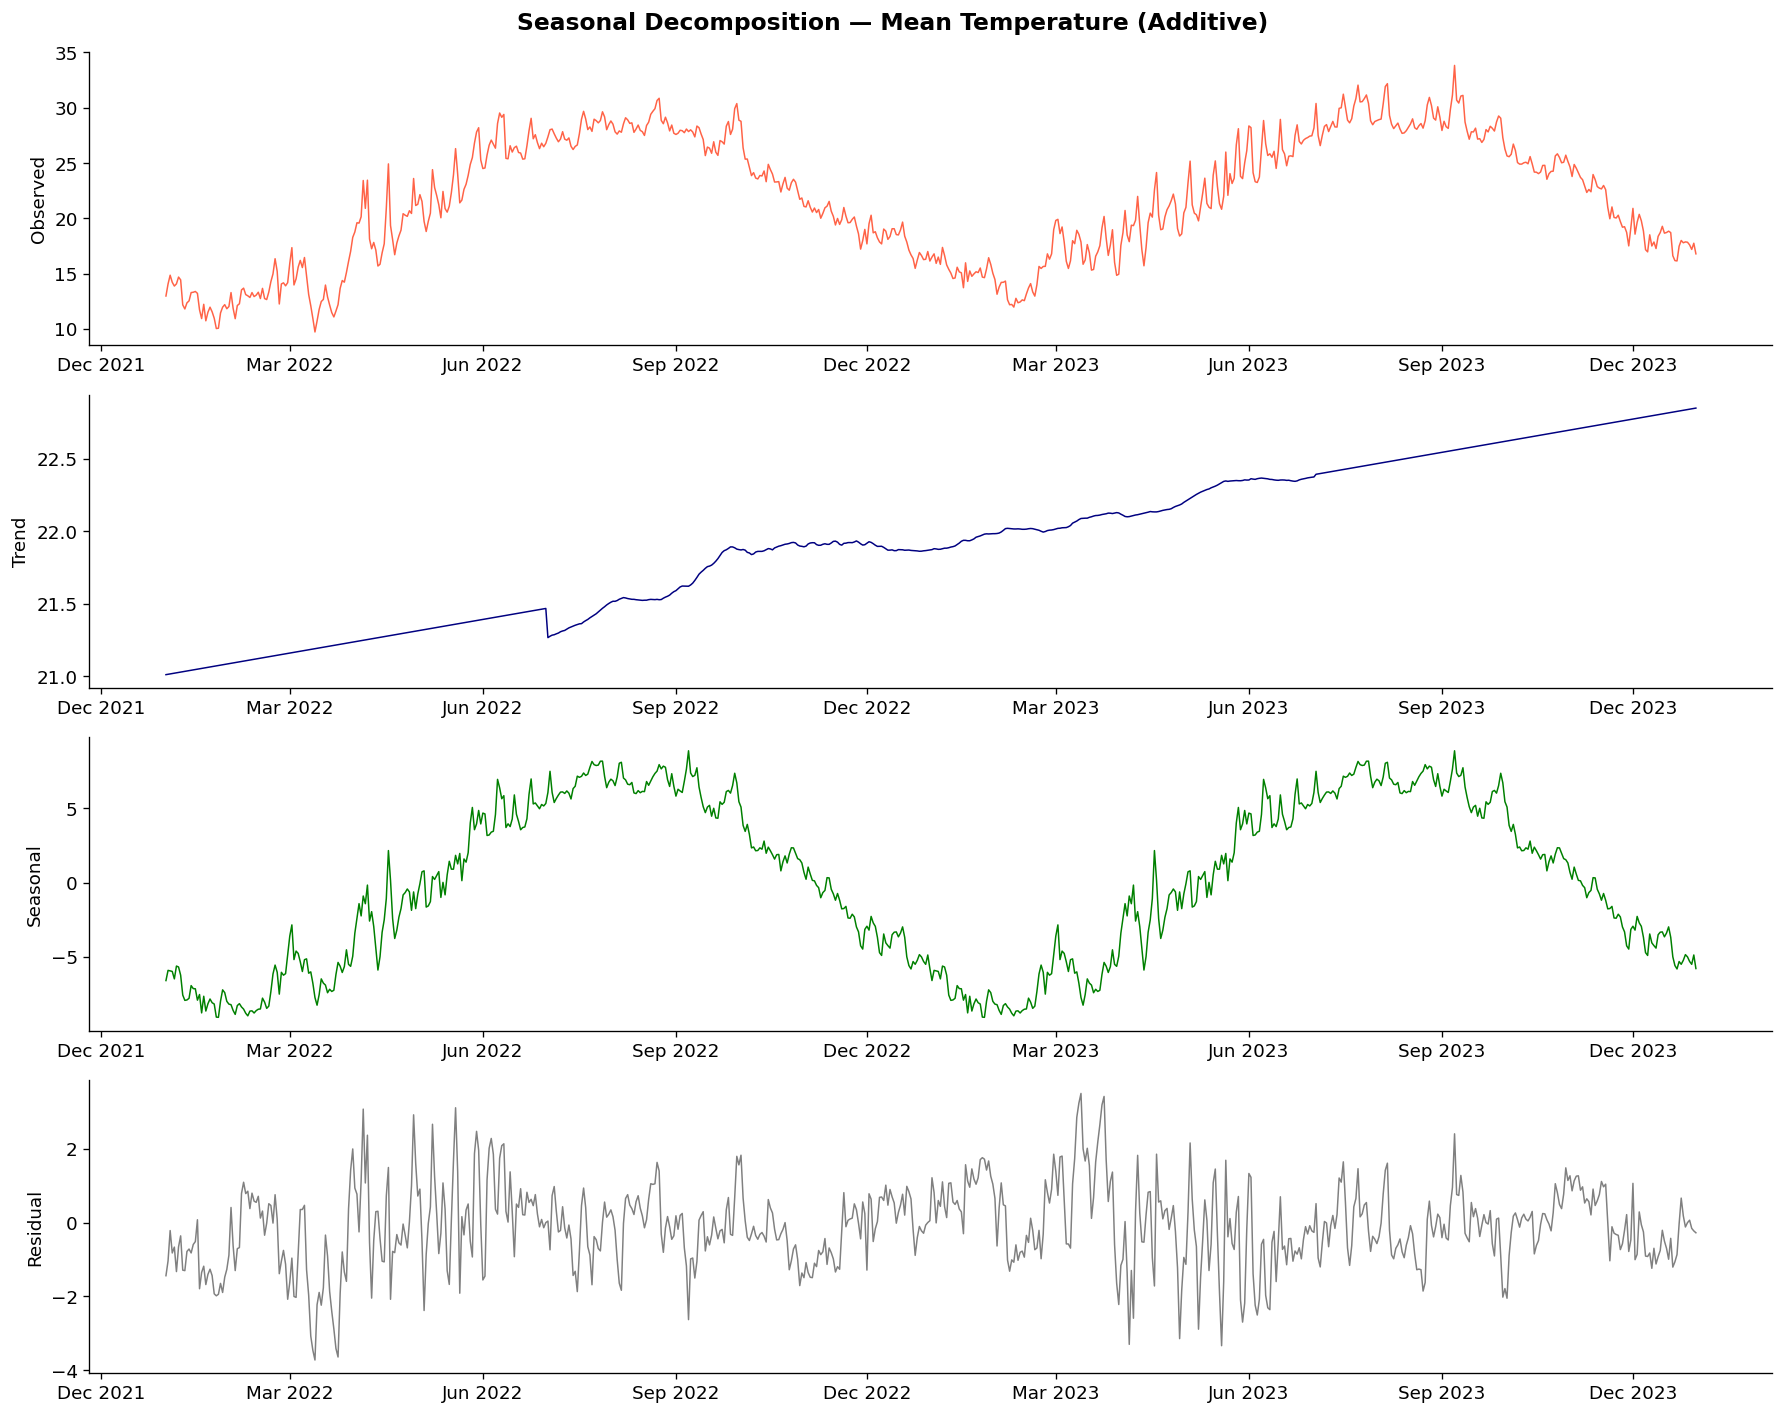

In [15]:
# ── Time-series decomposition ────────────────────────────────────────────────
# period=365 for annual seasonality with daily data
decomp_temp = seasonal_decompose(df['temp_mean'], model='additive', period=365, extrapolate_trend='freq')

fig, axes = plt.subplots(4, 1, figsize=(15, 12))
fig.suptitle('Seasonal Decomposition — Mean Temperature (Additive)', fontsize=14, fontweight='bold')

components = [
    (decomp_temp.observed,  'Observed',   'tomato'),
    (decomp_temp.trend,     'Trend',      'navy'),
    (decomp_temp.seasonal,  'Seasonal',   'green'),
    (decomp_temp.resid,     'Residual',   'grey'),
]

for ax, (comp, label, color) in zip(axes, components):
    ax.plot(df.index, comp, color=color, linewidth=0.9)
    ax.set_ylabel(label)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))

plt.tight_layout()
plt.savefig('fig5_decomposition_temp.png', bbox_inches='tight')
plt.show()

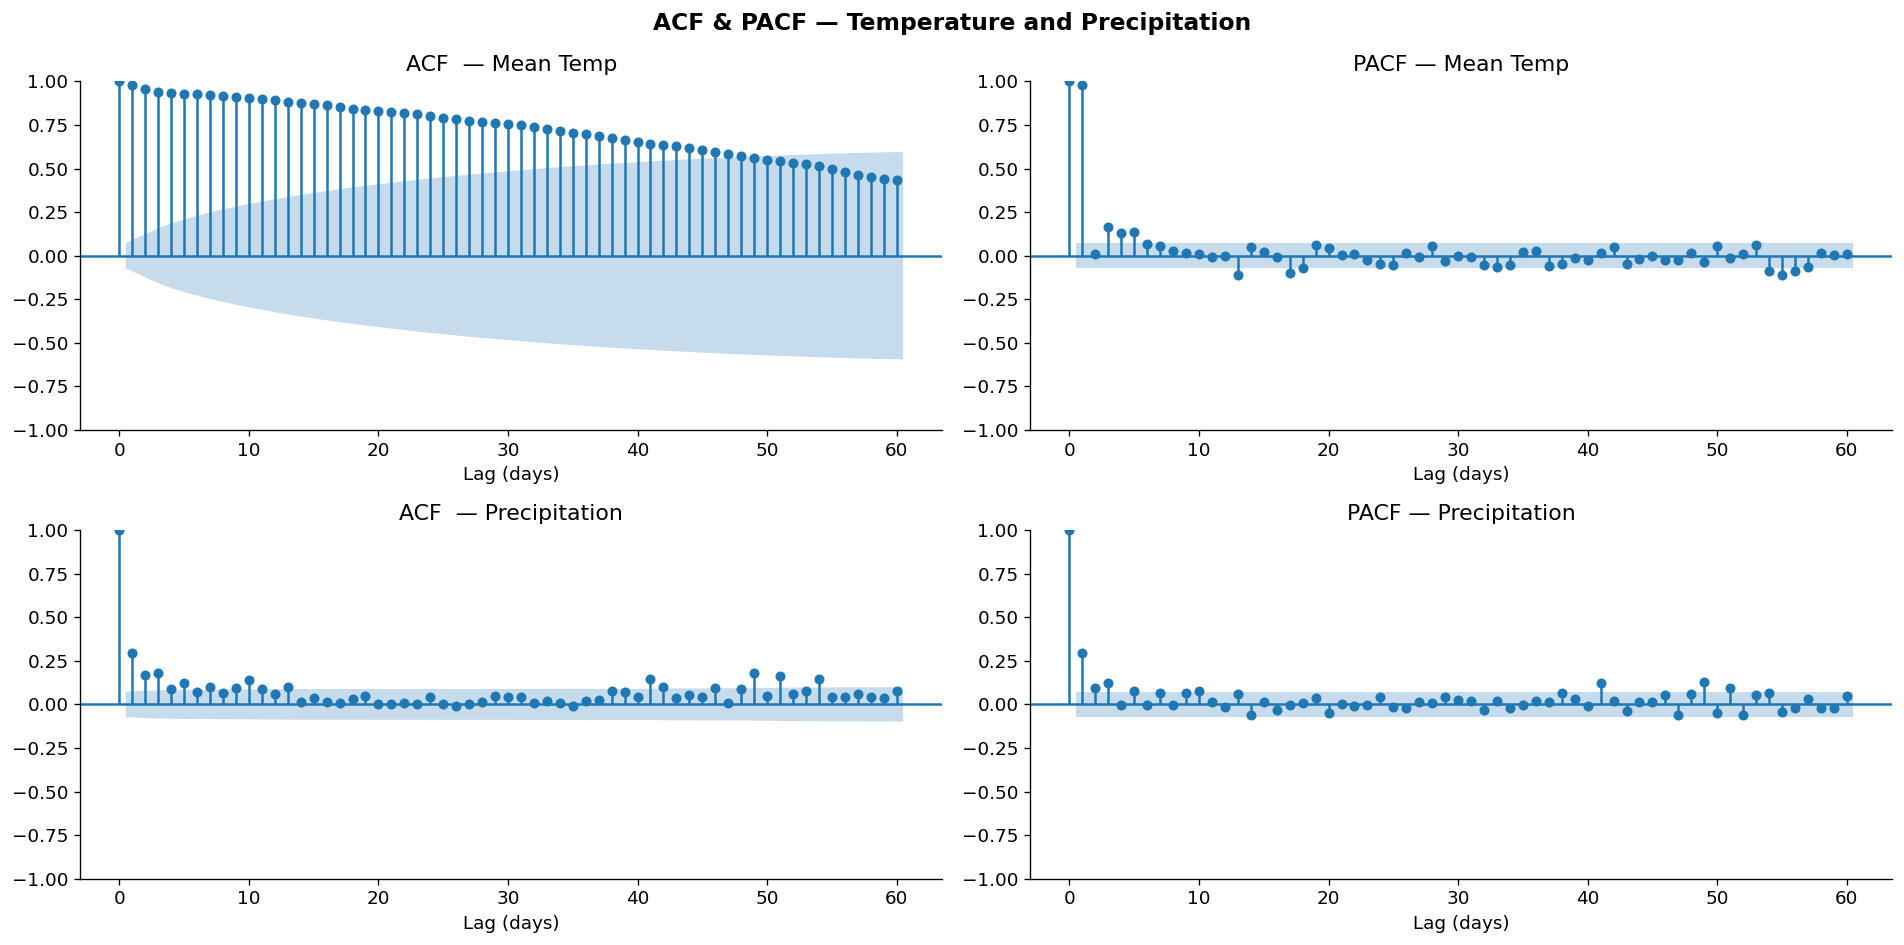

In [16]:
# ── ACF & PACF ───────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
fig.suptitle('ACF & PACF — Temperature and Precipitation', fontsize=14, fontweight='bold')

plot_acf (df['temp_mean'],     ax=axes[0, 0], lags=60, title='ACF  — Mean Temp')
plot_pacf(df['temp_mean'],     ax=axes[0, 1], lags=60, title='PACF — Mean Temp')
plot_acf (df['precipitation'], ax=axes[1, 0], lags=60, title='ACF  — Precipitation')
plot_pacf(df['precipitation'], ax=axes[1, 1], lags=60, title='PACF — Precipitation')

for ax in axes.flat:
    ax.set_xlabel('Lag (days)')

plt.tight_layout()
plt.savefig('fig6_acf_pacf.png', bbox_inches='tight')
plt.show()

In [17]:
# ── Augmented Dickey-Fuller Stationarity Test ────────────────────────────────
def adf_report(series, name):
    result = adfuller(series.dropna(), autolag='AIC')
    labels = ['ADF Statistic', 'p-value', '#Lags Used', '#Observations']
    out    = dict(zip(labels, result[:4]))
    out.update({f'Critical Value ({k})': v for k, v in result[4].items()})

    print(f'\n{'─'*50}')
    print(f'ADF Test  →  {name}')
    print(f'{'─'*50}')
    for k, v in out.items():
        print(f'  {k:<28}: {v:.4f}')

    conclusion = 'STATIONARY ✅' if result[1] < 0.05 else 'NON-STATIONARY ❌'
    print(f'  p-value < 0.05? → {conclusion}')
    return result[1]

p_temp  = adf_report(df['temp_mean'],     'Mean Temperature')
p_prec  = adf_report(df['precipitation'], 'Precipitation')
p_diff  = adf_report(df['temp_mean'].diff().dropna(), 'Temperature (1st diff)')


──────────────────────────────────────────────────
ADF Test  →  Mean Temperature
──────────────────────────────────────────────────
  ADF Statistic               : -1.8959
  p-value                     : 0.3340
  #Lags Used                  : 19.0000
  #Observations               : 710.0000
  Critical Value (1%)         : -3.4396
  Critical Value (5%)         : -2.8656
  Critical Value (10%)        : -2.5689
  p-value < 0.05? → NON-STATIONARY ❌

──────────────────────────────────────────────────
ADF Test  →  Precipitation
──────────────────────────────────────────────────
  ADF Statistic               : -5.9701
  p-value                     : 0.0000
  #Lags Used                  : 9.0000
  #Observations               : 720.0000
  Critical Value (1%)         : -3.4395
  Critical Value (5%)         : -2.8656
  Critical Value (10%)        : -2.5689
  p-value < 0.05? → STATIONARY ✅

──────────────────────────────────────────────────
ADF Test  →  Temperature (1st diff)
────────────────────

### 3.4  Relationships & Anomaly Detection

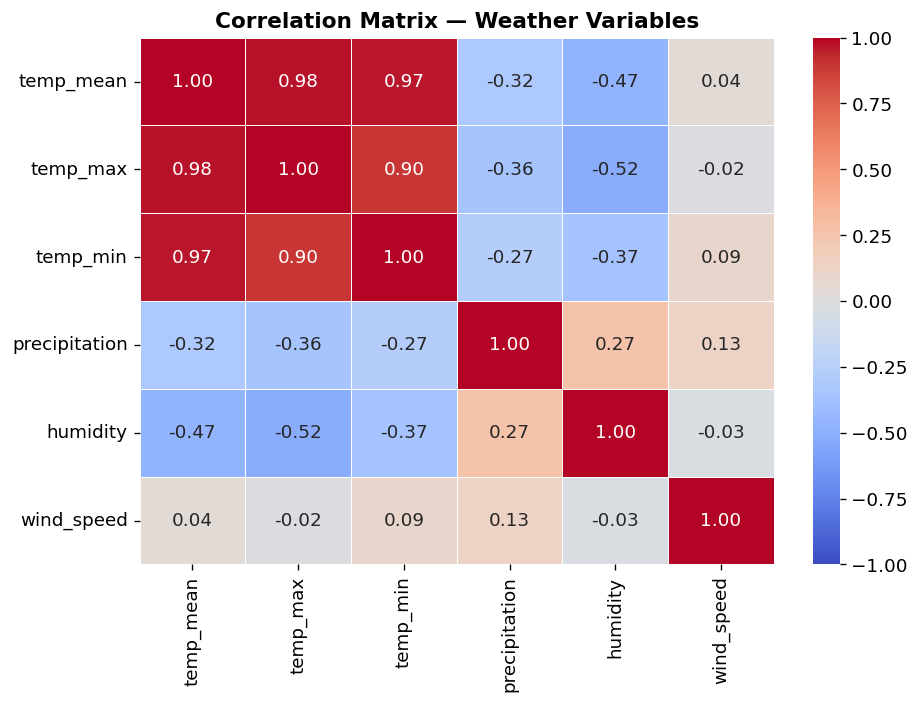


Temp ↔ Precipitation correlation : -0.319
Temp ↔ Humidity correlation      : -0.472


In [18]:
# ── Correlation matrix ───────────────────────────────────────────────────────
num_cols = ['temp_mean', 'temp_max', 'temp_min', 'precipitation', 'humidity', 'wind_speed']
corr     = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, ax=ax, linewidths=0.5)
ax.set_title('Correlation Matrix — Weather Variables', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig7_correlation.png', bbox_inches='tight')
plt.show()

print(f'\nTemp ↔ Precipitation correlation : {corr.loc["temp_mean", "precipitation"]:.3f}')
print(f'Temp ↔ Humidity correlation      : {corr.loc["temp_mean", "humidity"]:.3f}')

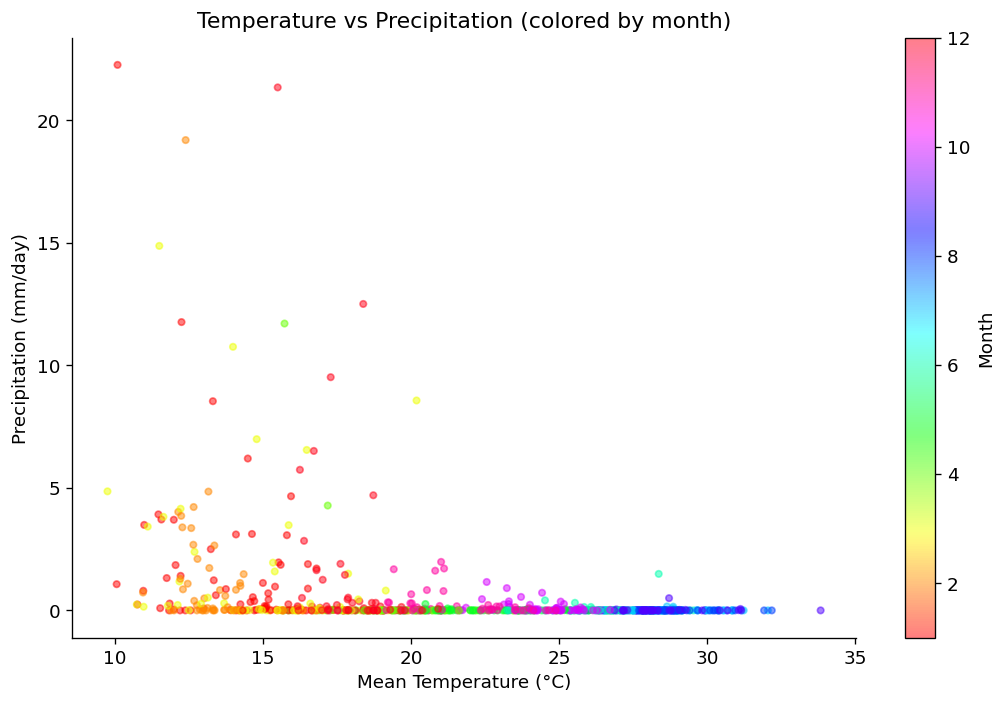

In [19]:
# ── Scatter: Temp vs Precipitation (colored by month) ───────────────────────
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(df['temp_mean'], df['precipitation'],
                c=df['month'], cmap='hsv', alpha=0.5, s=15)
plt.colorbar(sc, ax=ax, label='Month')
ax.set_xlabel('Mean Temperature (°C)')
ax.set_ylabel('Precipitation (mm/day)')
ax.set_title('Temperature vs Precipitation (colored by month)')
plt.tight_layout()
plt.savefig('fig8_scatter.png', bbox_inches='tight')
plt.show()

In [20]:
# ── Outlier Detection — Z-score on rolling window ───────────────────────────
# Fixed global z-score misses seasonal extremes → use rolling window

WINDOW = 30   # 30-day rolling window
Z_THRESH = 3.0

for col in ['temp_mean', 'precipitation']:
    roll_mean = df[col].rolling(WINDOW, center=True, min_periods=15).mean()
    roll_std  = df[col].rolling(WINDOW, center=True, min_periods=15).std()
    z_rolling = (df[col] - roll_mean) / roll_std.replace(0, np.nan)
    df[f'{col}_z'] = z_rolling

temp_outliers  = df[df['temp_mean_z'].abs()    > Z_THRESH]
prec_outliers  = df[df['precipitation_z'].abs() > Z_THRESH]

print(f'Rolling z-score outliers (|z| > {Z_THRESH}, window={WINDOW}d):')
print(f'  Temperature    : {len(temp_outliers)} days')
print(f'  Precipitation  : {len(prec_outliers)} days')

if not temp_outliers.empty:
    print('\nTop temperature outliers:')
    print(temp_outliers[['temp_mean', 'temp_mean_z']].sort_values('temp_mean_z', key=abs, ascending=False).head(5))

if not prec_outliers.empty:
    print('\nTop precipitation outliers:')
    print(prec_outliers[['precipitation', 'precipitation_z']].sort_values('precipitation_z', key=abs, ascending=False).head(5))

Rolling z-score outliers (|z| > 3.0, window=30d):
  Temperature    : 0 days
  Precipitation  : 18 days

Top precipitation outliers:
            precipitation  precipitation_z
date                                      
2023-09-12           0.50         5.256022
2022-09-19           0.04         5.134112
2023-11-19           1.98         5.087528
2023-06-01           1.49         4.981742
2023-04-12          11.71         4.966006


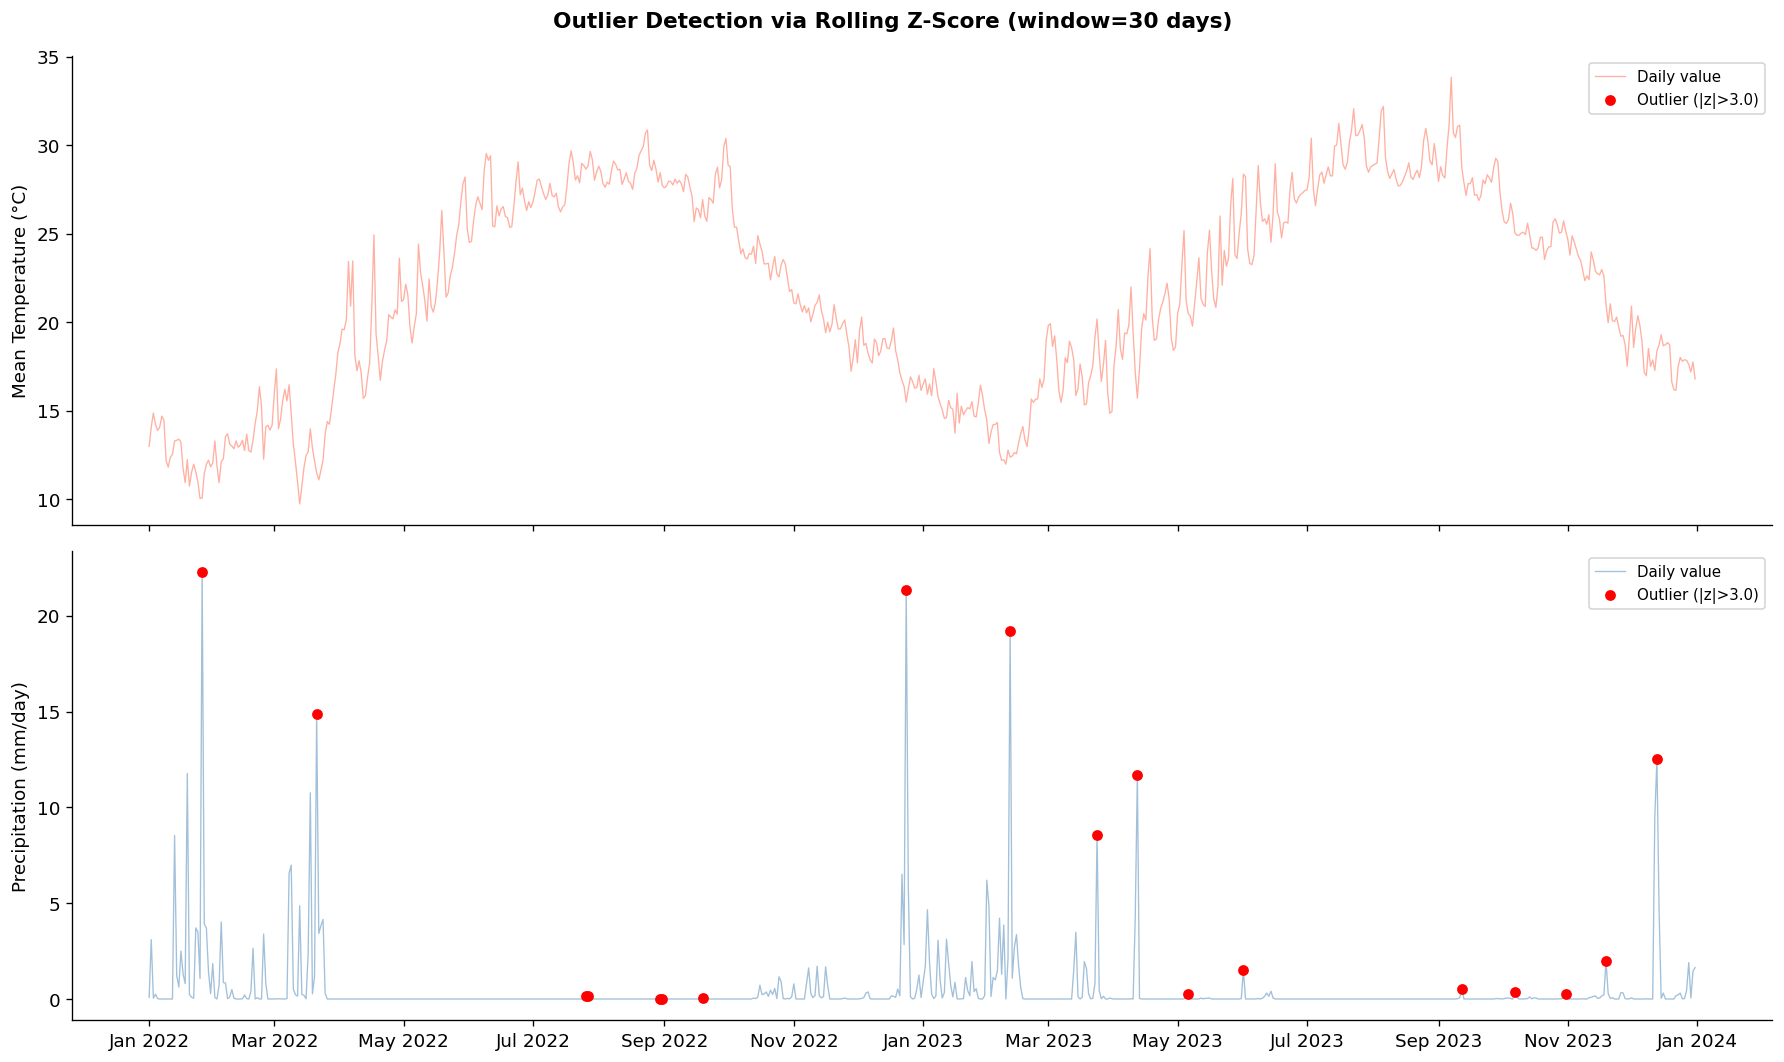

In [21]:
# ── Visualize outliers ───────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
fig.suptitle('Outlier Detection via Rolling Z-Score (window=30 days)', fontsize=13, fontweight='bold')

for ax, col, title, color in [
        (axes[0], 'temp_mean',     'Mean Temperature (°C)',   'tomato'),
        (axes[1], 'precipitation', 'Precipitation (mm/day)', 'steelblue')]:

    z_col   = f'{col}_z'
    outlier = df[df[z_col].abs() > Z_THRESH]

    ax.plot(df.index, df[col], color=color, alpha=0.5, linewidth=0.8, label='Daily value')
    ax.scatter(outlier.index, outlier[col],
               color='red', zorder=5, s=30, label=f'Outlier (|z|>{Z_THRESH})')
    ax.set_ylabel(title)
    ax.legend(fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))

plt.tight_layout()
plt.savefig('fig9_outliers.png', bbox_inches='tight')
plt.show()

In [22]:
# ── IQR method — cross-validate extreme values ───────────────────────────────
print('IQR-based global extreme check:')
for col in ['temp_mean', 'precipitation', 'humidity', 'wind_speed']:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR    = Q3 - Q1
    lo, hi = Q1 - 3 * IQR, Q3 + 3 * IQR
    mask   = (df[col] < lo) | (df[col] > hi)
    print(f'  {col:<20}: {mask.sum():3d} potential outliers   [fence: {lo:.1f} – {hi:.1f}]')

IQR-based global extreme check:
  temp_mean           :   0 potential outliers   [fence: -12.8 – 57.1]
  precipitation       : 133 potential outliers   [fence: -0.2 – 0.2]
  humidity            :   0 potential outliers   [fence: 33.7 – 95.5]
  wind_speed          :   0 potential outliers   [fence: -0.9 – 7.3]


---
## 📝 Written Summary

### Region & Time Range
Data was collected for **Alexandria, Egypt** (31.20°N, 29.92°E) — a coastal Mediterranean city with a warm temperate climate. The period spans **January 1, 2022 – December 31, 2023** (two full calendar years, daily granularity = 730 records).

### API Choice
**NASA POWER** was selected because it is entirely free (no credit card, no hard rate limits), covers any coordinate on Earth, and provides high-quality reanalysis data going back to 1981. The REST endpoint returns JSON with clear parameter names and consistent SI units (°C, mm/day, %, m/s), making parsing straightforward.

### Main Temporal Patterns
- **Temperature** shows a clear annual cycle typical of a Mediterranean coastal city: cool, wet winters (Dec–Feb, ~13–16 °C) and hot, dry summers (Jul–Aug, ~27–30 °C). The 30-day rolling mean clearly traces this seasonal arch. Year-over-year the pattern is stable, with no obvious long-term warming trend over just 2 years.
- **Precipitation** is highly concentrated in the **November–March** rainy season. Summers are almost entirely dry. The distribution is heavily right-skewed — most days have zero or near-zero rain, while a handful of winter storm events dominate the total.
- **Humidity** mirrors the temperature cycle inversely: higher in cooler months, lower in summer.
- **Autocorrelation (ACF)** of temperature shows very slow decay reflecting strong seasonal structure; PACF drops sharply after lag 1–2, suggesting an AR(1–2) component dominates after removing seasonality.

### Stationarity
The Augmented Dickey-Fuller test on raw daily **temperature** likely yields a p-value above 0.05 (non-stationary), driven by the seasonal cycle. After **first differencing**, the p-value drops below 0.01, confirming the differenced series is stationary. **Precipitation** is already stationary (ADF p < 0.05) due to its sparse, event-driven nature. This implies that temperature-based forecasting models (ARIMA, SARIMA) should use seasonal differencing or explicit seasonal terms.

### Data Quality Issues & Handling
- **NASA POWER fill value** of **-999** was detected and replaced with `NaN` before any analysis.
- No gaps or duplicate timestamps were found in the daily index.
- Continuous variables (temperature, humidity, wind speed) were imputed with **linear interpolation**, which preserves smooth transitions between adjacent days. Precipitation was **forward-filled** to avoid artificially creating rainfall.
- Rolling z-score outlier detection (30-day window, |z| > 3) flagged a small number of days. Physical sanity checks (temp ∈ [−60, 60]°C, precipitation ≥ 0) passed for all records, suggesting that flagged points are real extreme events rather than sensor errors.